### Scarico il DATASET da Kaggle tramite API

In [ ]:
from google.colab import userdata
import os

# Legge i segreti in modo sicuro
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

import kagglehub

path = kagglehub.dataset_download("asaniczka/top-spotify-songs-in-73-countries-daily-updated")

print("Path to dataset files:", path)

100%|██████████| 162M/162M [00:02<00:00, 82.2MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/asaniczka/top-spotify-songs-in-73-countries-daily-updated/versions/608


## Carichiamo il DATASET

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(path + '/universal_top_spotify_songs.csv')

print(f"Shape: {df.shape}")
print(f"Colonne: {df.columns.tolist()}")
df

Shape: (2110316, 25)
Colonne: ['spotify_id', 'name', 'artists', 'daily_rank', 'daily_movement', 'weekly_movement', 'country', 'snapshot_date', 'popularity', 'is_explicit', 'duration_ms', 'album_name', 'album_release_date', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']


,spotify_id,name,artists,daily_rank,daily_movement,weekly_movement,country,snapshot_date,popularity,is_explicit,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,2RkZ5LkEzeHGRsmDqKwmaJ,Ordinary,Alex Warren,1,1,0,NaN,2025-06-11,95,False,...,2,-6.141,1,0.0600,0.704000,0.000007,0.0550,0.391,168.115,3
1,42UBPzRMh5yyz0EDPr6fr1,Manchild,Sabrina Carpenter,2,-1,48,NaN,2025-06-11,89,True,...,7,-5.087,1,0.0572,0.122000,0.000000,0.3170,0.811,123.010,4
2,0FTmksd2dxiE5e3rWyJXs6,back to friends,sombr,3,0,1,NaN,2025-06-11,98,False,...,1,-2.291,1,0.0301,0.000094,0.000088,0.0929,0.235,92.855,4
3,7so0lgd0zP2Sbgs2d7a1SZ,Die With A Smile,"Lady Gaga, Bruno Mars",4,0,-1,NaN,2025-06-11,91,False,...,6,-7.727,0,0.0317,0.289000,0.000000,0.1260,0.498,157.964,3
4,6dOtVTDdiauQNBQEDOtlAB,BIRDS OF A FEATHER,Billie Eilish,5,1,0,NaN,2025-06-11,100,False,...,2,-10.171,1,0.0358,0.200000,0.060800,0.1170,0.438,104.978,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2110311,0AYt6NMyyLd0rLuvr0UkMH,Slime You Out (feat. SZA),"Drake, SZA",46,4,0,AE,2023-10-18,84,True,...,5,-9.243,0,0.0502,0.508000,0.000000,0.2590,0.105,88.880,3
2110312,2Gk6fi0dqt91NKvlzGsmm7,SAY MY GRACE (feat. Travis Scott),"Offset, Travis Scott",47,3,0,AE,2023-10-18,80,True,...,10,-5.060,1,0.0452,0.058500,0.000000,0.1320,0.476,121.879,4
2110313,26b3oVLrRUaaybJulow9kz,People,Libianca,48,2,0,AE,2023-10-18,88,False,...,10,-7.621,0,0.0678,0.551000,0.000013,0.1020,0.693,124.357,5
2110314,5ydjxBSUIDn26MFzU3asP4,Rainy Days,V,49,1,0,AE,2023-10-18,88,False,...,9,-8.016,0,0.0875,0.739000,0.000000,0.1480,0.282,74.828,4


## Analisi del Dataset

### df.info

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2110316 entries, 0 to 2110315
Data columns (total 25 columns):
 #   Column              Dtype  
---  ------              -----  
 0   spotify_id          object 
 1   name                object 
 2   artists             object 
 3   daily_rank          int64  
 4   daily_movement      int64  
 5   weekly_movement     int64  
 6   country             object 
 7   snapshot_date       object 
 8   popularity          int64  
 9   is_explicit         bool   
 10  duration_ms         int64  
 11  album_name          object 
 12  album_release_date  object 
 13  danceability        float64
 14  energy              float64
 15  key                 int64  
 16  loudness            float64
 17  mode                int64  
 18  speechiness         float64
 19  acousticness        float64
 20  instrumentalness    float64
 21  liveness            float64
 22  valence             float64
 23  tempo               float64
 24  time_signature      int6

### Valori Nulli

In [ ]:
print("\n VALORI MANCANTI ")
print(df.isnull().sum())


 VALORI MANCANTI 
spotify_id                0
name                     30
artists                  29
daily_rank                0
daily_movement            0
weekly_movement           0
country               28908
snapshot_date             0
popularity                0
is_explicit               0
duration_ms               0
album_name              822
album_release_date      659
danceability              0
energy                    0
key                       0
loudness                  0
mode                      0
speechiness               0
acousticness              0
instrumentalness          0
liveness                  0
valence                   0
tempo                     0
time_signature            0
dtype: int64


In [ ]:
colonne_utili = ['country', 'name', 'artists', 'daily_rank',
                 'snapshot_date', 'popularity',
                 'danceability', 'energy', 'valence', 'tempo',
                 'acousticness', 'speechiness', 'instrumentalness',
                 'liveness', 'loudness', 'duration_ms',
                 'is_explicit', 'key', 'mode', 'time_signature']

df_clean = df[colonne_utili]
df_clean

,country,name,artists,daily_rank,snapshot_date,popularity,danceability,energy,valence,tempo,acousticness,speechiness,instrumentalness,liveness,loudness,duration_ms,is_explicit,key,mode,time_signature
0,NaN,Ordinary,Alex Warren,1,2025-06-11,95,0.368,0.694,0.391,168.115,0.704000,0.0600,0.000007,0.0550,-6.141,186964,False,2,1,3
1,NaN,Manchild,Sabrina Carpenter,2,2025-06-11,89,0.731,0.685,0.811,123.010,0.122000,0.0572,0.000000,0.3170,-5.087,213645,True,7,1,4
2,NaN,back to friends,sombr,3,2025-06-11,98,0.436,0.723,0.235,92.855,0.000094,0.0301,0.000088,0.0929,-2.291,199032,False,1,1,4
3,NaN,Die With A Smile,"Lady Gaga, Bruno Mars",4,2025-06-11,91,0.519,0.601,0.498,157.964,0.289000,0.0317,0.000000,0.1260,-7.727,251667,False,6,0,3
4,NaN,BIRDS OF A FEATHER,Billie Eilish,5,2025-06-11,100,0.747,0.507,0.438,104.978,0.200000,0.0358,0.060800,0.1170,-10.171,210373,False,2,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2110311,AE,Slime You Out (feat. SZA),"Drake, SZA",46,2023-10-18,84,0.483,0.408,0.105,88.880,0.508000,0.0502,0.000000,0.2590,-9.243,310490,True,5,0,3
2110312,AE,SAY MY GRACE (feat. Travis Scott),"Offset, Travis Scott",47,2023-10-18,80,0.773,0.635,0.476,121.879,0.058500,0.0452,0.000000,0.1320,-5.060,173253,True,10,1,4
2110313,AE,People,Libianca,48,2023-10-18,88,0.573,0.422,0.693,124.357,0.551000,0.0678,0.000013,0.1020,-7.621,184791,False,10,0,5
2110314,AE,Rainy Days,V,49,2023-10-18,88,0.633,0.454,0.282,74.828,0.739000,0.0875,0.000000,0.1480,-8.016,179560,False,9,0,4


In [ ]:
print('VALORI MANCANTI')
print(df_clean.isnull().sum())

VALORI MANCANTI
country             28908
name                   30
artists                29
daily_rank              0
snapshot_date           0
popularity              0
danceability            0
energy                  0
valence                 0
tempo                   0
acousticness            0
speechiness             0
instrumentalness        0
liveness                0
loudness                0
duration_ms             0
is_explicit             0
key                     0
mode                    0
time_signature          0
dtype: int64


### Elimino i NaN del dataset; Country è il dato principale che ci serve, insieme a nome del brano e artista

In [ ]:
# Eliminiamo righe con NaN in colonne essenziali
df_clean = df_clean.dropna(subset=['country', 'name', 'artists'])
df_clean = df_clean.reset_index(drop=True)

print(f"Righe prima: 2110316")
print(f"Righe dopo:  {df_clean.shape[0]}")
print(f"NaN rimasti: {df_clean.isnull().sum().sum()}")

Righe prima: 2110316
Righe dopo:  2081378
NaN rimasti: 0


In [ ]:
# Percentuale di Dati Persi dopo il Drop NaN
righe_prima = 2110316
righe_dopo = df_clean.shape[0]
righe_eliminate = righe_prima - righe_dopo
percentuale_persa = (righe_eliminate / righe_prima) * 100
percentuale_rimasta = 100 - percentuale_persa

print(f"Righe prima:      {righe_prima:,}")
print(f"Righe eliminate:  {righe_eliminate:,}")
print(f"Righe rimaste:    {righe_dopo:,}")
print(f"Percentuale persa:    {percentuale_persa:.2f}%")
print(f"Percentuale rimasta:  {percentuale_rimasta:.2f}%")
print(f"Dataset ancora valido — perso solo il {percentuale_persa:.2f}% dei dati!")

Righe prima:      2,110,316
Righe eliminate:  28,938
Righe rimaste:    2,081,378
Percentuale persa:    1.37%
Percentuale rimasta:  98.63%
Dataset ancora valido — perso solo il 1.37% dei dati!


### Outlier

In [ ]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
daily_rank,2081378.0,25.493027,14.429009,1.000000,13.0000,25.000000,38.000000,50.000
popularity,2081378.0,75.729926,15.744068,0.000000,65.0000,79.000000,88.000000,100.000
danceability,2081378.0,0.676378,0.143772,0.000000,0.5810,0.700000,0.780000,0.988
energy,2081378.0,0.649111,0.168752,0.000020,0.5520,0.669000,0.767000,0.998
valence,2081378.0,0.546649,0.230838,0.000000,0.3700,0.548000,0.733000,0.992
tempo,2081378.0,122.107151,27.811143,0.000000,100.0190,119.966000,140.022000,236.089
acousticness,2081378.0,0.275094,0.250730,0.000003,0.0675,0.192000,0.437000,0.996
speechiness,2081378.0,0.095801,0.091591,0.000000,0.0385,0.058300,0.112000,0.957
instrumentalness,2081378.0,0.023016,0.113369,0.000000,0.0000,0.000001,0.000099,0.995
liveness,2081378.0,0.170630,0.124787,0.013900,0.0961,0.122000,0.204000,0.983


In [ ]:
print(f"Brani con tempo = 0: {(df_clean['tempo'] == 0).sum()}")
print(f"Brani con time_signature = 0: {(df_clean['time_signature'] == 0).sum()}")
print(f"Brani con duration < 30.000ms: {(df_clean['duration_ms'] < 30000).sum()}") # 3 secondi
print(f"Brani con duration > 600.000ms (10 min): {(df_clean['duration_ms'] > 600000).sum()}") # 10 minuti
print(f"Brani con popularity = 0: {(df_clean['popularity'] == 0).sum()}")

Brani con tempo = 0: 1
Brani con time_signature = 0: 1
Brani con duration < 30.000ms: 1
Brani con duration > 600.000ms (10 min): 1024
Brani con popularity = 0: 10315


In [ ]:
# Eliminiamo tutti outlier
df_clean = df_clean[df_clean['tempo'] != 0]
df_clean = df_clean[df_clean['time_signature'] != 0]
df_clean = df_clean[df_clean['duration_ms'] >= 30000]

In [ ]:
df_clean[df_clean['duration_ms'] > 600000][['artists','name']]

,artists,name
12205,Neuf Voix,"Secessioni, Pt. 3"
112846,"Bonez MC, Nate57, Jugglerz, AchtVier, AK 33, A...",bissu dumm ¿ MEGALODON REMIX
116377,"Bonez MC, Nate57, Jugglerz, AchtVier, AK 33, A...",bissu dumm ¿ MEGALODON REMIX
119928,"Bonez MC, Nate57, Jugglerz, AchtVier, AK 33, A...",bissu dumm ¿ MEGALODON REMIX
123475,"Bonez MC, Nate57, Jugglerz, AchtVier, AK 33, A...",bissu dumm ¿ MEGALODON REMIX
...,...,...
2073796,"Dj GBR, Mc IG, MC Ryan SP, MC PH, Mc Davi, Mc ...",Let's Go 4
2075023,"Dj GBR, Mc IG, MC Ryan SP, MC PH, Mc Davi, Mc ...",Let's Go 4
2077387,"Dj GBR, Mc IG, MC Ryan SP, MC PH, Mc Davi, Mc ...",Let's Go 4
2078614,"Dj GBR, Mc IG, MC Ryan SP, MC PH, Mc Davi, Mc ...",Let's Go 4


In [ ]:
print(df_clean[df_clean['duration_ms'] > 600000][['name', 'artists', 'duration_ms']].head(10))

                                name  \
12205              Secessioni, Pt. 3   
112846  bissu dumm ¿ MEGALODON REMIX   
116377  bissu dumm ¿ MEGALODON REMIX   
119928  bissu dumm ¿ MEGALODON REMIX   
123475  bissu dumm ¿ MEGALODON REMIX   
127025  bissu dumm ¿ MEGALODON REMIX   
130577  bissu dumm ¿ MEGALODON REMIX   
134130  bissu dumm ¿ MEGALODON REMIX   
137674  bissu dumm ¿ MEGALODON REMIX   
141217  bissu dumm ¿ MEGALODON REMIX   

                                                  artists  duration_ms  
12205                                           Neuf Voix      1296000  
112846  Bonez MC, Nate57, Jugglerz, AchtVier, AK 33, A...      1114155  
116377  Bonez MC, Nate57, Jugglerz, AchtVier, AK 33, A...      1114155  
119928  Bonez MC, Nate57, Jugglerz, AchtVier, AK 33, A...      1114155  
123475  Bonez MC, Nate57, Jugglerz, AchtVier, AK 33, A...      1114155  
127025  Bonez MC, Nate57, Jugglerz, AchtVier, AK 33, A...      1114155  
130577  Bonez MC, Nate57, Jugglerz, AchtVier, AK

In [ ]:
print(f"Brani unici > 10 min: {df_clean[df_clean['duration_ms'] > 600000]['name'].nunique()}")
print(f"In quanti paesi appaiono: {df_clean[df_clean['duration_ms'] > 600000]['country'].nunique()}")

Brani unici > 10 min: 25
In quanti paesi appaiono: 16


In [ ]:
# 25 Brani sono pochi; possiamo eliminarli
df_clean = df_clean[df_clean['duration_ms'] <= 600000]

In [ ]:
df_clean[df_clean['popularity'] == 0][['name', 'artists', 'country', 'snapshot_date']]


,name,artists,country,snapshot_date
137,Solcito,"Miguel Bueno, Juan Duque",VE,2025-06-11
1047,Solcito,"Miguel Bueno, Juan Duque",PE,2025-06-11
1072,Solcito,"Miguel Bueno, Juan Duque",PA,2025-06-11
1951,מלכת הדור,Omer Adam,IL,2025-06-11
1952,השיר שאת אהבת,Omer Adam,IL,2025-06-11
...,...,...,...,...
2078687,Tu hai kahan,AUR,PK,2023-10-18
2079132,Jaga Jaga,"VicK, Babi",NG,2023-10-18
2079680,Tu hai kahan,AUR,IN,2023-10-18
2081337,Rockstar,Jay Chang,AE,2023-10-18


In [ ]:
# Verifichiamo quanti brani unici sono
print(f"Brani unici con popularity = 0: {df_clean[df_clean['popularity'] == 0]['name'].nunique()}")
print(f"Paesi coinvolti: {df_clean[df_clean['popularity'] == 0]['country'].nunique()}")
print(f"Percentuale sul totale: {(df_clean['popularity'] == 0).sum() / df_clean.shape[0] * 100:.2f}%")


Brani unici con popularity = 0: 3203
Paesi coinvolti: 72
Percentuale sul totale: 0.50%


In [ ]:
# Sono lo 0,5 % -> Eliminiamo
df_clean = df_clean[df_clean['popularity'] != 0]

In [ ]:
# Reset Index
df_clean = df_clean.reset_index(drop=True)

In [ ]:
# Verifica
print(f"Righe prima:   2081378")
print(f"Righe rimaste: {df_clean.shape[0]}")
print(f"Righe eliminate: {2081378 - df_clean.shape[0]}")
print(f"Percentuale rimasta: {df_clean.shape[0]/2081378*100:.2f}%")
print(f"Dataset pulito!")

Righe prima:   2081378
Righe rimaste: 2070048
Righe eliminate: 11330
Percentuale rimasta: 99.46%
Dataset pulito!


### Normalizzazione dei BPM

In [ ]:
bpm_max = df_clean.iloc[df_clean['tempo'].idxmax()]
bpm_max

,20505
country,CZ
name,No Time (feat. Ektor)
artists,"Calin, Ektor"
daily_rank,49
snapshot_date,2025-06-06
popularity,58
danceability,0.562
energy,0.665
valence,0.958
tempo,236.089


In [ ]:
#Decidere la soglia dopo cui Spotify raddoppia il BPM
print(f"Brani con tempo > 150: {(df_clean['tempo'] > 150).sum()}")
print(f"Brani con tempo > 160: {(df_clean['tempo'] > 160).sum()}")
print(f"Brani con tempo > 180: {(df_clean['tempo'] > 180).sum()}")

Brani con tempo > 150: 348861
Brani con tempo > 160: 210273
Brani con tempo > 180: 53346


In [ ]:
# Normalizzazione con soglia 180
df_clean['tempo'] = df_clean['tempo'].apply(
    lambda x: x/2 if x >= 180 else x
)

print(f"Tempo max dopo normalizzazione: {df_clean['tempo'].max():.1f}")
print(f"Tempo medio: {df_clean['tempo'].mean():.1f}")

Tempo max dopo normalizzazione: 180.0
Tempo medio: 119.7


In [ ]:
# Vediamo i brani con tempo più alto
top_bpm = df_clean.nlargest(5,'tempo')[['name', 'artists', 'tempo']].drop_duplicates(subset=['name'])
print(top_bpm.to_string(index=False))

     name           artists   tempo
soft date Kukon, Hubi, Hvll 179.999
  Falling            Mvriol 179.997


In [ ]:
# Ricarichiamo df_clean senza normalizzazione
df_clean = df[colonne_utili].copy()
df_clean = df_clean.dropna(subset=['country', 'name', 'artists'])
df_clean = df_clean[df_clean['tempo'] != 0]
df_clean = df_clean[df_clean['time_signature'] != 0]
df_clean = df_clean[df_clean['duration_ms'] >= 30000]
df_clean = df_clean[df_clean['duration_ms'] <= 600000]
df_clean = df_clean[df_clean['popularity'] != 0]
df_clean = df_clean.reset_index(drop=True)

# Applichiamo normalizzazione UNA SOLA VOLTA
df_clean['tempo'] = df_clean['tempo'].apply(
    lambda x: x/2 if x >= 180 else x
)

print(f"Tempo max: {df_clean['tempo'].max():.1f}")
print(f"Tempo medio: {df_clean['tempo'].mean():.1f}")

Tempo max: 180.0
Tempo medio: 119.7


In [ ]:
# Vediamo il valore esatto massimo
print(f"Tempo max esatto: {df_clean['tempo'].max()}")

# Quanti brani hanno tempo >= 178?
print(df_clean[df_clean['tempo'] >= 178][['name', 'artists', 'tempo']].drop_duplicates(subset=['name']).head(5))

Tempo max esatto: 179.999
              name                               artists    tempo
157   Amor de Vago                 La T y La M, Malandro  179.984
169    MASNA REMIX  FMK, Emilia, Nicki Nicole, Tiago PZK  179.932
255      ШОВКОВИЦЯ             IVAN LIULENOV, DAMNITSKYI  178.135
1142          MUTT                           Leon Thomas  179.787
1284           M&M                            Neton Vega  178.837


In [ ]:
# Salvo il Dataset Pulito fino a qui
from google.colab import drive
drive.mount('/content/drive')

import os
PATH = '/content/drive/MyDrive/FestivalFit/'
os.makedirs(PATH, exist_ok=True)

df_clean.to_csv(PATH + 'countries_clean.csv', index=False)
print(f"Dataset salvato! {df_clean.shape}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset salvato! (2070048, 20)


## EDA

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PATH = '/content/drive/MyDrive/FestivalFit/'

df_clean = pd.read_csv(PATH + 'countries_clean.csv')

print(f'Shape: {df_clean.shape}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape: (2070048, 20)


### Istogrammi delle Audio Features

In [ ]:
df_clean.columns

Index(['country', 'name', 'artists', 'daily_rank', 'snapshot_date',
       'popularity', 'danceability', 'energy', 'valence', 'tempo',
       'acousticness', 'speechiness', 'instrumentalness', 'liveness',
       'loudness', 'duration_ms', 'is_explicit', 'key', 'mode',
       'time_signature'],
      dtype='object')

In [ ]:
features_tutte = ['danceability', 'energy', 'valence', 'tempo',
                  'acousticness', 'speechiness', 'instrumentalness',
                  'liveness', 'mode', 'is_explicit', 'time_signature','popularity']

df_paese_temp = df_clean.groupby('country')[features_tutte].mean()
cv = (df_paese_temp.std() / df_paese_temp.mean() * 100).sort_values(ascending=False)

print(cv.round(2))

instrumentalness    68.00
is_explicit         49.86
speechiness         29.92
acousticness        28.54
mode                25.46
liveness            14.50
popularity          10.48
valence             10.06
energy               7.77
danceability         6.45
tempo                3.79
time_signature       2.42
dtype: float64


In [ ]:
#Time_signature è una caratteristica più tecninca; non interessa al promoter
#Anche key è già più tecnico; non lo includiamo

### Convertiamo is_explicit in numero

In [ ]:
df_clean['is_explicit'] = df_clean['is_explicit'].astype(int)

print(df_clean['is_explicit'].value_counts())

is_explicit
0    1397215
1     672833
Name: count, dtype: int64


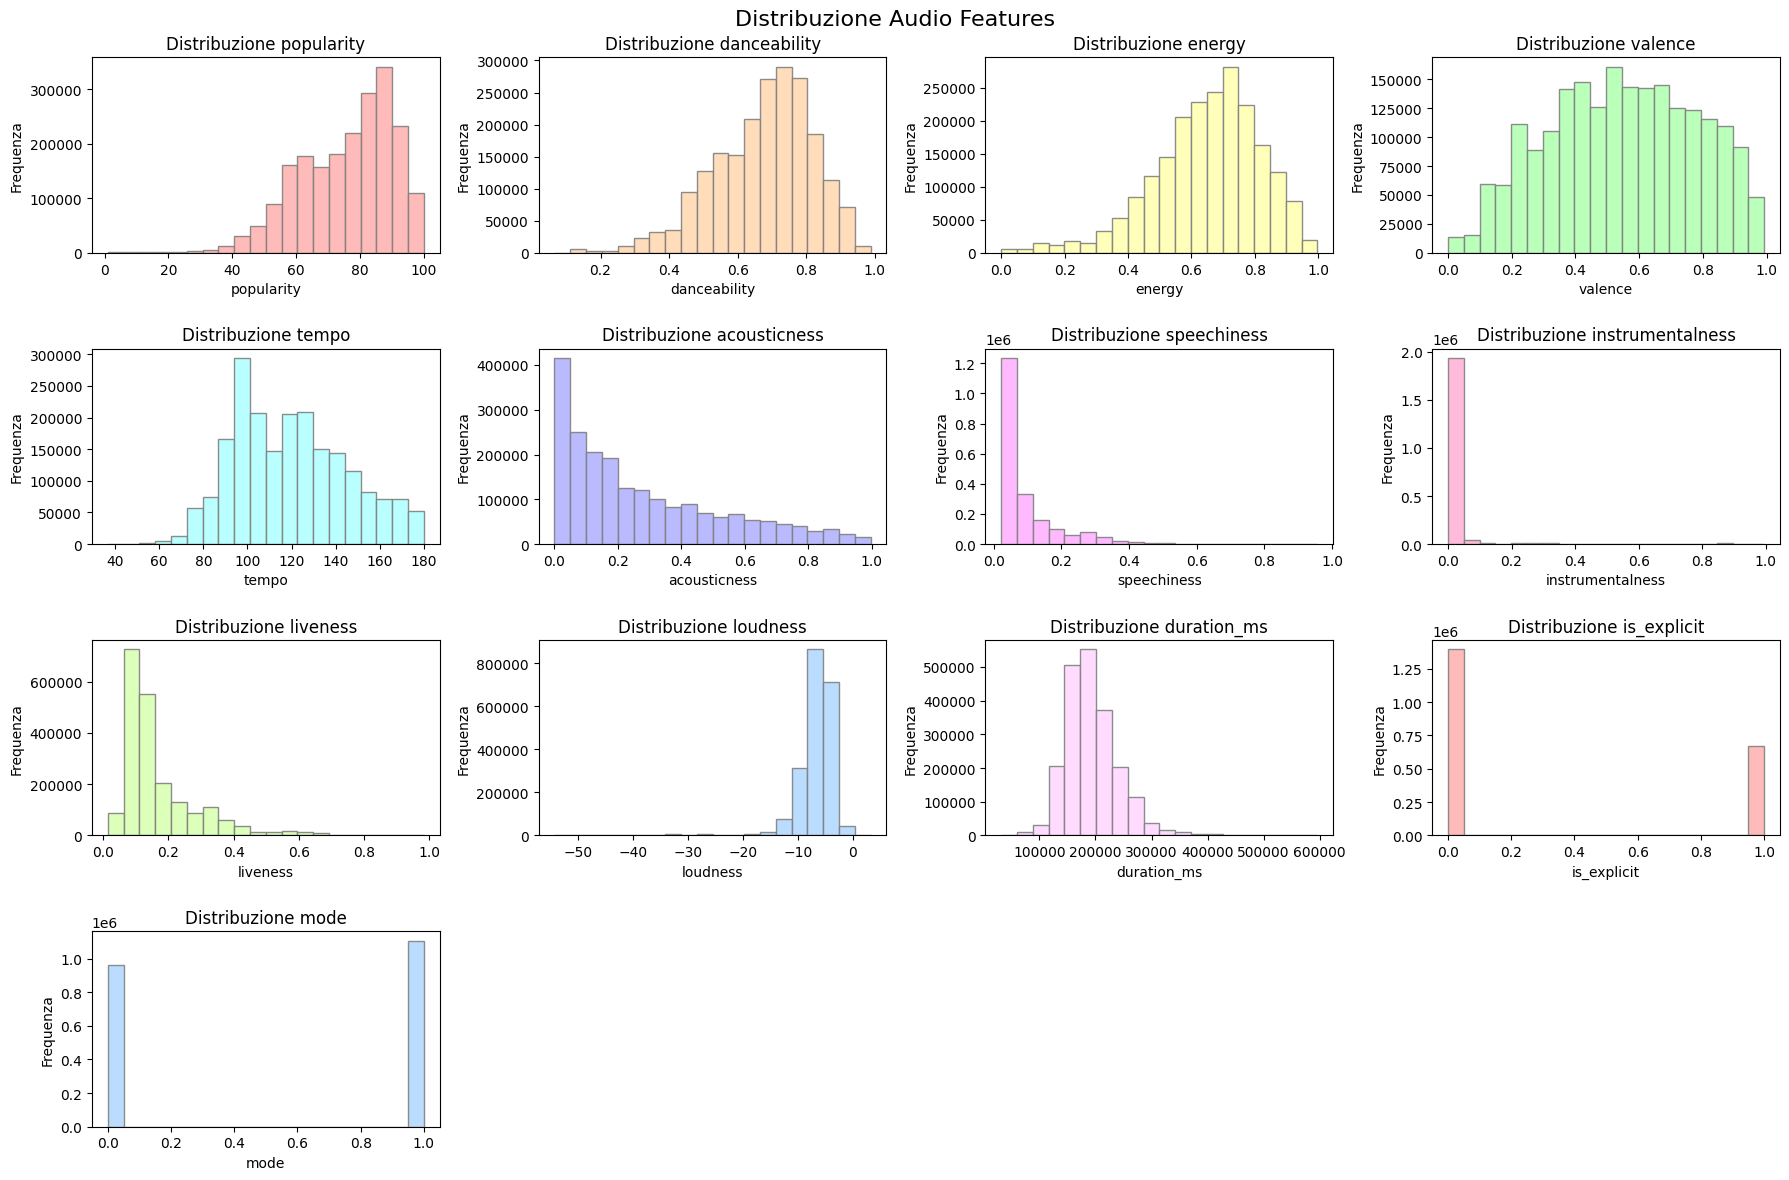

In [ ]:
features = [
        'popularity',
       'danceability', 'energy', 'valence', 'tempo',
       'acousticness', 'speechiness', 'instrumentalness', 'liveness',
       'loudness', 'duration_ms','is_explicit','mode']

colori_pastello = [
    '#FFB3B3',  # rosa
    '#FFD9B3',  # pesca
    '#FFFFB3',  # giallo
    '#B3FFB3',  # verde menta
    '#B3FFFF',  # azzurro
    '#B3B3FF',  # lavanda
    '#FFB3FF',  # lilla
    '#FFB3D9',  # rosa antico
    '#D9FFB3',  # verde lime
    '#B3D9FF',  # celeste
    '#FFD9FF', #
    '#FFB3B3',
    '#B3D9FF'
]

fig, axes = plt.subplots(4,4, figsize = (18,12))
axes = axes.flatten()

for i, feature in enumerate(features):
    axes[i].hist(df_clean[feature], bins=20,
                 color=colori_pastello[i], edgecolor='gray', alpha=0.9)
    axes[i].set_title(f'Distribuzione {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frequenza')

#Nascondo subplot vuoti
for j in range(len(features),len(axes)):
     axes[j].set_visible(False)

plt.suptitle('Distribuzione Audio Features', fontsize=16)
plt.tight_layout()
plt.show()


### Correlation Matrix

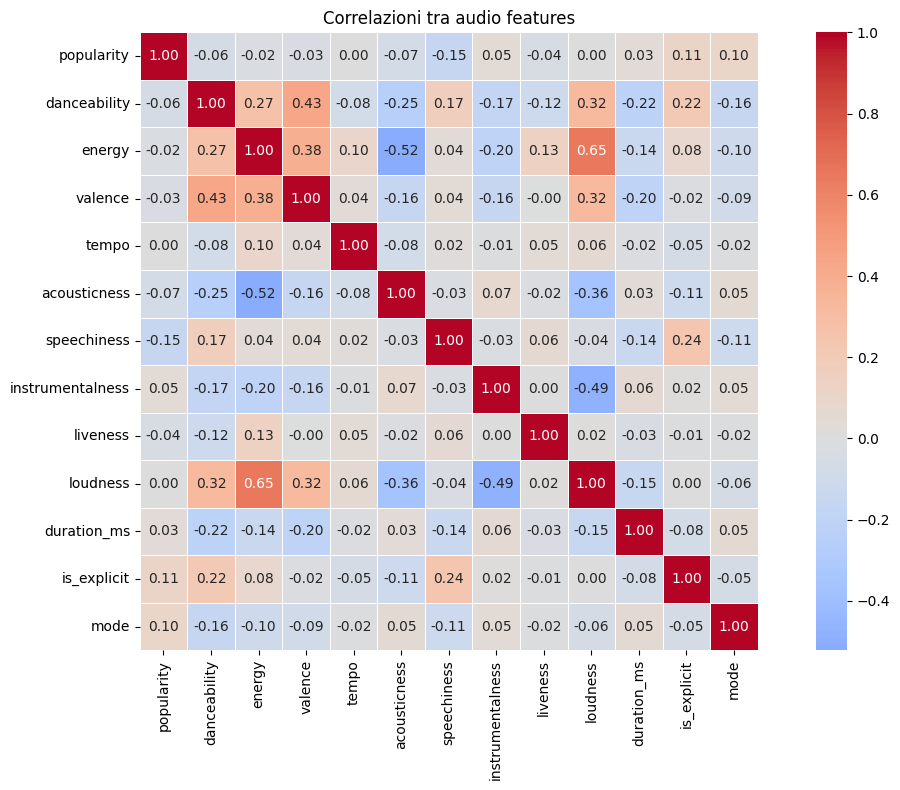

In [ ]:
plt.figure (figsize=(12,8))
corr = df_clean[features].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square = True, linewidth=0.5)
plt.title('Correlazioni tra audio features')
plt.tight_layout()
plt.show()

### Variazioni delle Features fra Paesi

=== Variazione relativa tra paesi (%) ===
instrumentalness    68.00
is_explicit         49.86
speechiness         29.92
acousticness        28.54
mode                25.46
liveness            14.50
valence             10.06
duration_ms          9.99
energy               7.77
danceability         6.45
tempo                3.79
loudness           -10.82
dtype: float64


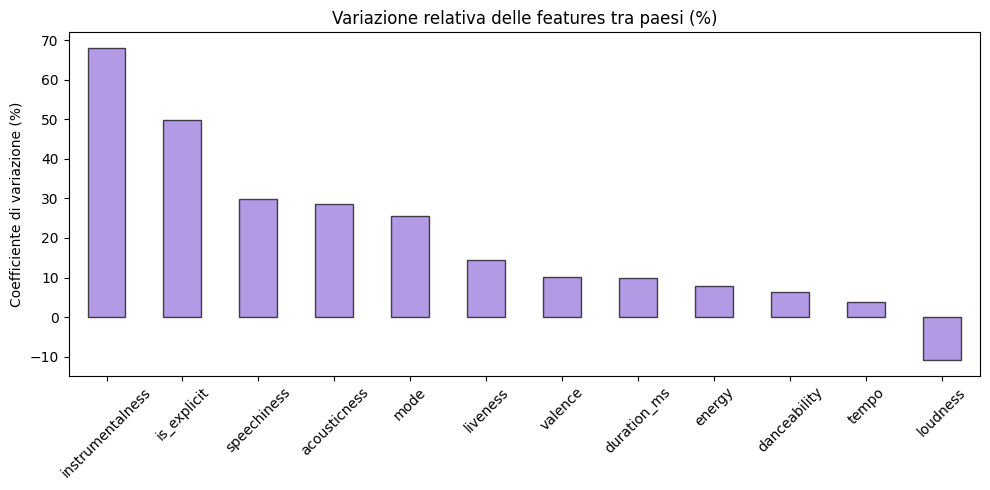

In [ ]:
# Variazione delle features tra paesi
features_all = ['danceability', 'energy', 'valence', 'tempo',
                'acousticness', 'speechiness', 'instrumentalness',
                'liveness', 'loudness', 'duration_ms','is_explicit','mode']

# Media per paese
df_paese_var = df_clean.groupby('country')[features_all].mean()

# Coefficiente di variazione (std/mean) per ogni feature
df_paese_var = df_clean.groupby('country')[features_all].mean()

cv = (df_paese_var.std() / df_paese_var.mean() * 100).sort_values(ascending=False)

print("=== Variazione relativa tra paesi (%) ===")
print(cv.round(2))

# Grafico
plt.figure(figsize=(10, 5))
cv.plot(kind='bar', color='mediumpurple', edgecolor='black', alpha=0.7)
plt.title('Variazione relativa delle features tra paesi (%)')
plt.ylabel('Coefficiente di variazione (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
std_loudness = df_paese_var['loudness'].std()
mean_loudness = df_paese_var['loudness'].mean()
print(f"Loudness std tra paesi: {std_loudness:.3f}")
print(f"Loudness media: {mean_loudness:.3f}")
print(f"Loudness min paese: {df_paese_var['loudness'].min():.3f}")
print(f"Loudness max paese: {df_paese_var['loudness'].max():.3f}")
range_loudness = df_paese_var['loudness'].max() - df_paese_var['loudness'].min()
print(f"Range: {range_loudness:.3f}")
print(f"Variazione di Duration_ms in percentuale: {(std_loudness/range_loudness)*100:.3f}")

Loudness std tra paesi: 0.732
Loudness media: -6.767
Loudness min paese: -8.724
Loudness max paese: -4.471
Range: 4.253
Variazione di Duration_ms in percentuale: 17.215


### Abbiamo deciso quali Features mantenere per il Clustering

✅ danceability

✅ energy

✅ valence

✅ tempo

✅ acousticness

✅ speechiness

✅ instrumentalness

✅ liveness

✅ is_explicit

✅ mode

❌ loudness → correlata con energy

❌ duration_ms → non rilevante per gusto locale

❌ popularity → non dipende dal sound

## Calcoliamo il PROFILO SONORO per PAESE

In [ ]:
features_cluster = ['danceability', 'energy', 'valence', 'tempo',
                    'acousticness', 'speechiness', 'instrumentalness',
                    'liveness', 'is_explicit', 'mode']

# Media pesata per daily_rank invece di media semplice
df_paese = df_clean.groupby('country').apply(
    lambda x: pd.Series({
        feat: np.average(x[feat], weights=1/x['daily_rank'])
        for feat in features_cluster
    })
).round(3)

print(f"✅ Paesi: {df_paese.shape[0]}")
print(df_paese.head(3))

✅ Paesi: 72
         danceability  energy  valence    tempo  acousticness  speechiness  \
country                                                                      
AE              0.645   0.646    0.532  123.787         0.202        0.067   
AR              0.689   0.663    0.649  120.234         0.260        0.091   
AT              0.673   0.679    0.578  124.288         0.200        0.091   

         instrumentalness  liveness  is_explicit   mode  
country                                                  
AE                  0.014     0.156        0.337  0.654  
AR                  0.037     0.190        0.328  0.473  
AT                  0.020     0.165        0.331  0.616  


/tmp/ipykernel_2246/2016024178.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_paese = df_clean.groupby('country').apply(


### Grafici Top 20 Paesi per Features

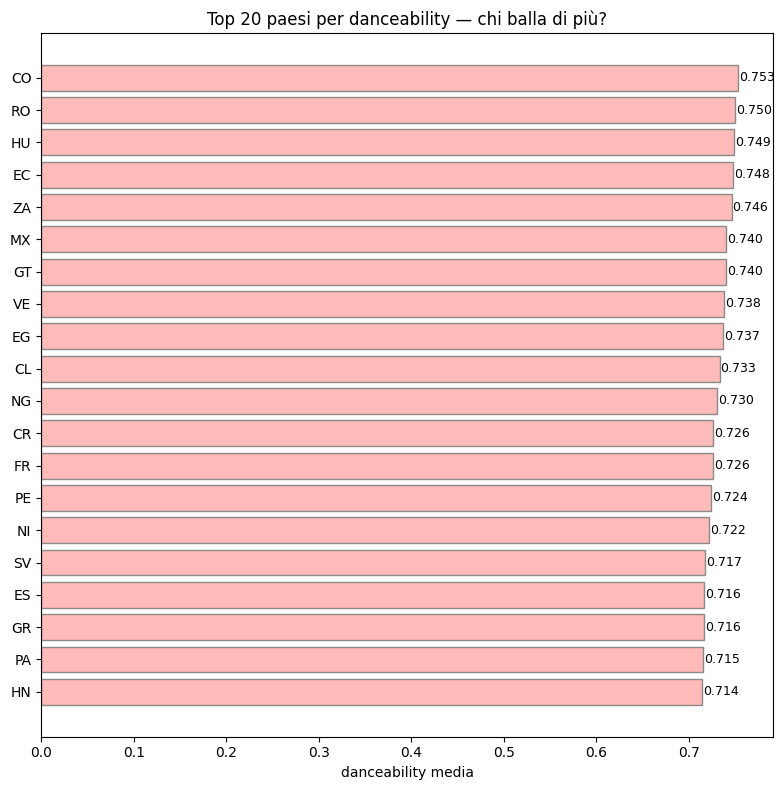

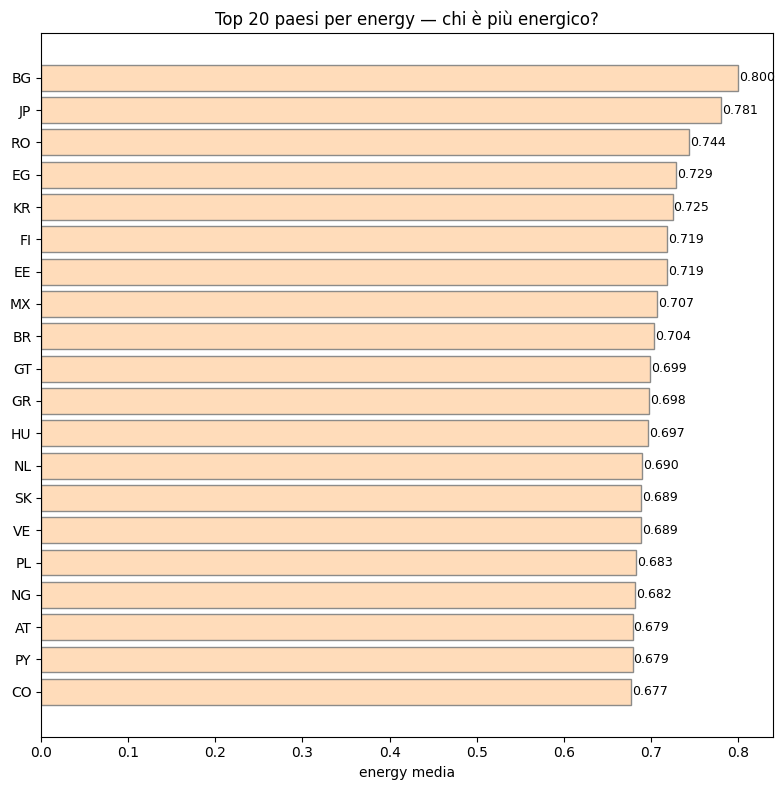

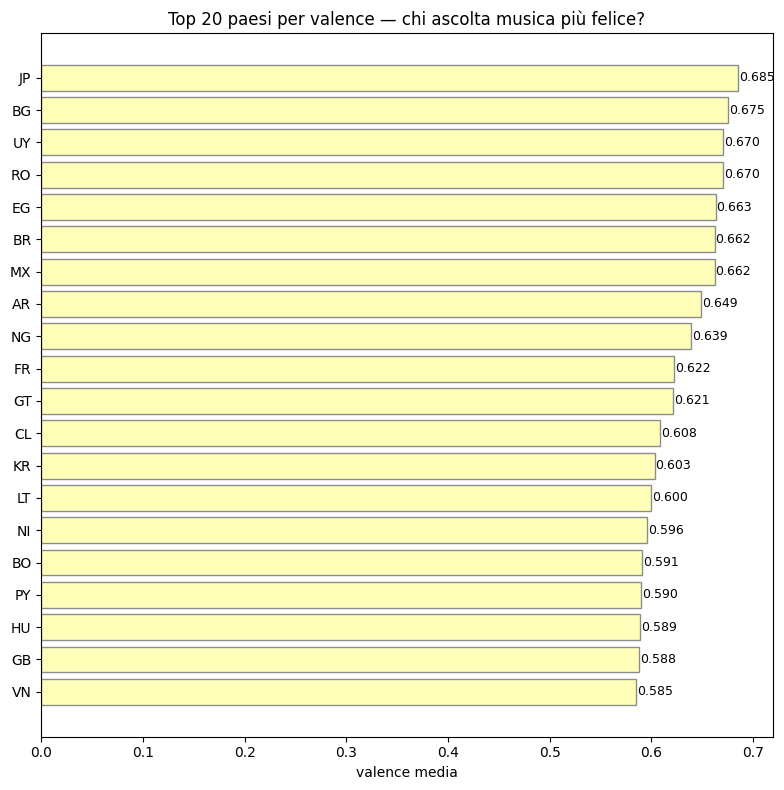

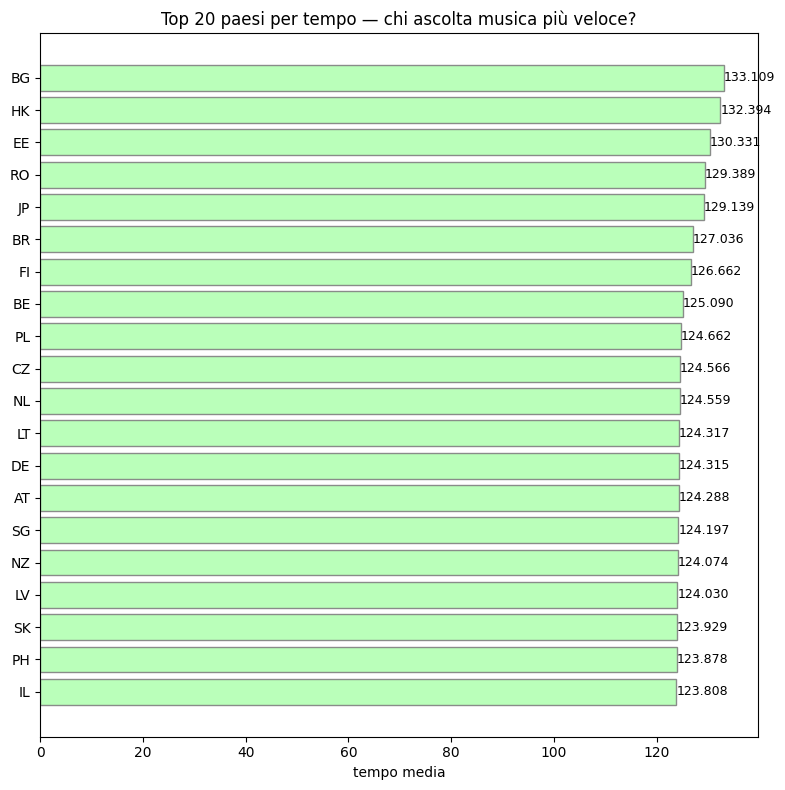

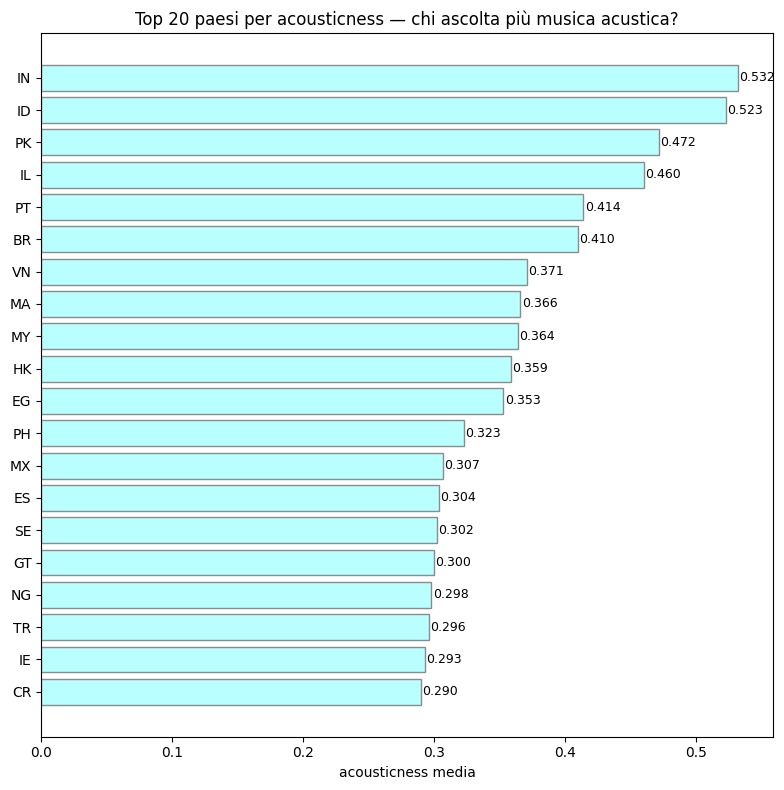

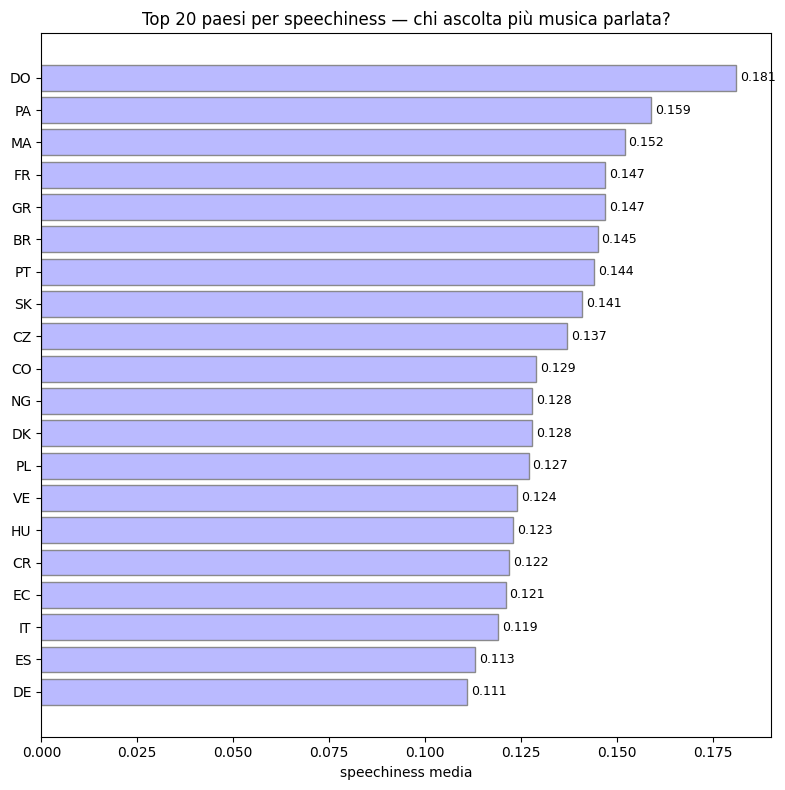

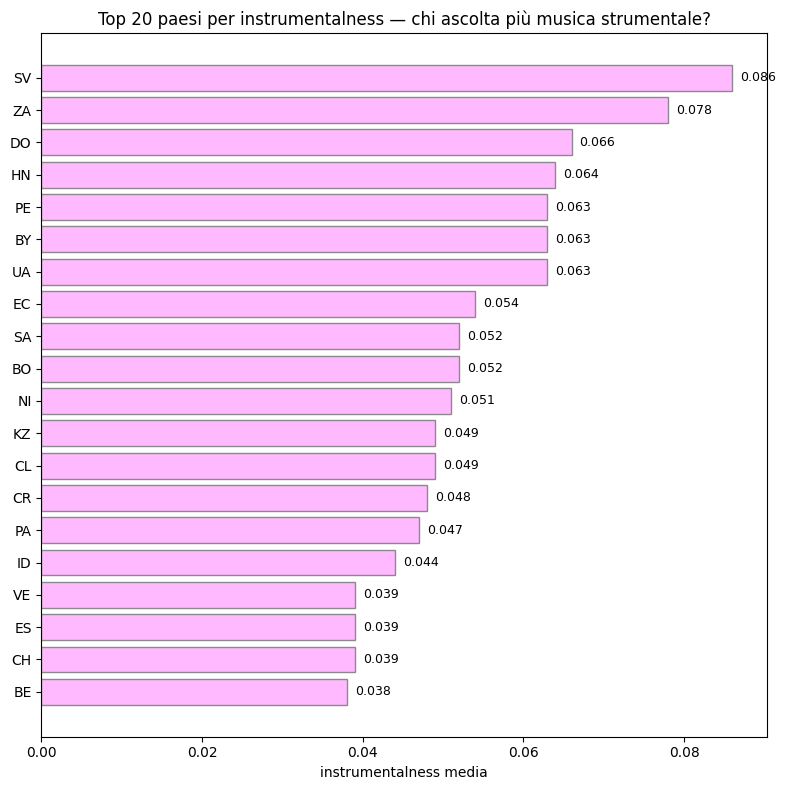

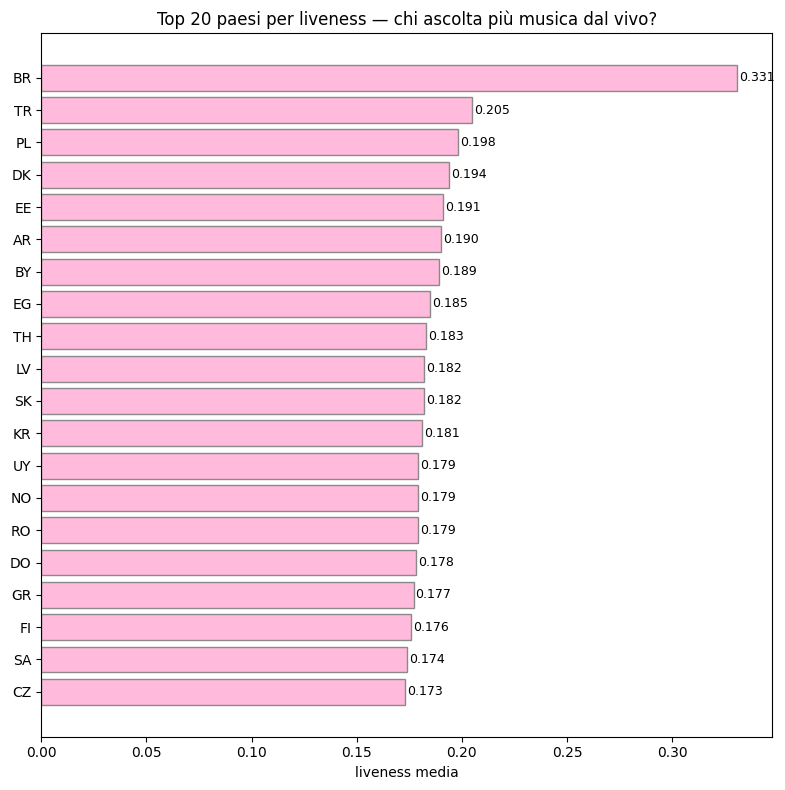

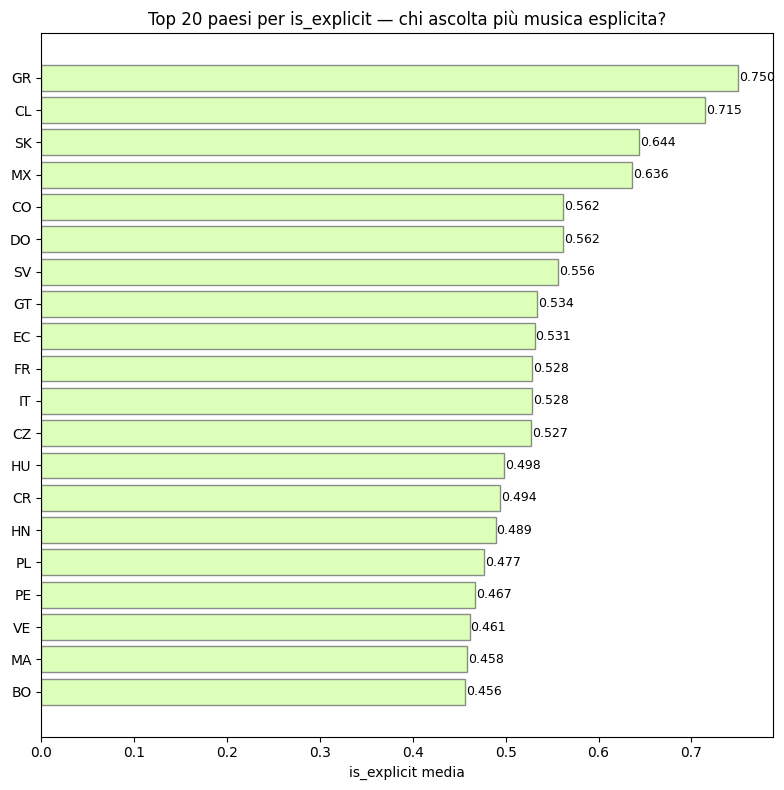

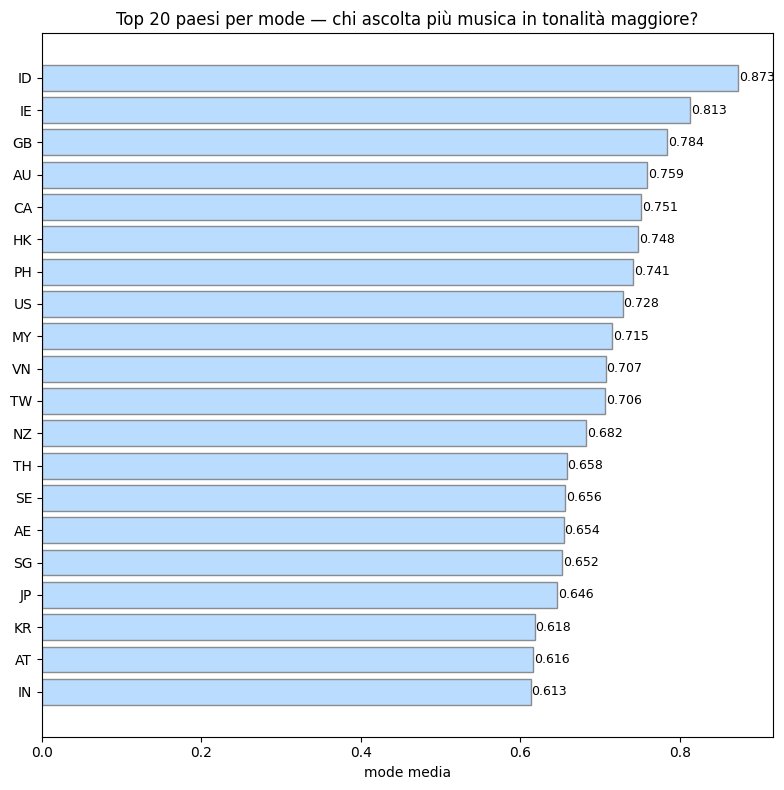

In [ ]:
colori = [
    '#FFB3B3',  # rosa
    '#FFD9B3',  # pesca
    '#FFFFB3',  # giallo
    '#B3FFB3',  # verde menta
    '#B3FFFF',  # azzurro
    '#B3B3FF',  # lavanda
    '#FFB3FF',  # lilla
    '#FFB3D9',  # rosa antico
    '#D9FFB3',  # verde lime
    '#B3D9FF',  # celeste
]

titoli = {
    'danceability': 'chi balla di più?',
    'energy': 'chi è più energico?',
    'valence': 'chi ascolta musica più felice?',
    'tempo': 'chi ascolta musica più veloce?',
    'acousticness': 'chi ascolta più musica acustica?',
    'speechiness': 'chi ascolta più musica parlata?',
    'instrumentalness': 'chi ascolta più musica strumentale?',
    'liveness': 'chi ascolta più musica dal vivo?',
    'is_explicit': 'chi ascolta più musica esplicita?',
    'mode': 'chi ascolta più musica in tonalità maggiore?'
}

for i, feature in enumerate(features_cluster):
    top_20 = df_paese[feature].sort_values(ascending=False).head(20)

    plt.figure(figsize=(8,8))
    bars = plt.barh(top_20.index, top_20.values,
                    color=colori[i], edgecolor='gray', alpha=0.9)
    plt.xlabel(f'{feature} media')
    plt.title(f'Top 20 paesi per {feature} — {titoli[feature]}')
    plt.gca().invert_yaxis()

    for bar, val in zip(bars, top_20.values):
        plt.text(val + 0.001, bar.get_y() + bar.get_height()/2,
                 f'{val:.3f}', va='center', fontsize=9)

    plt.tight_layout()
    plt.show()

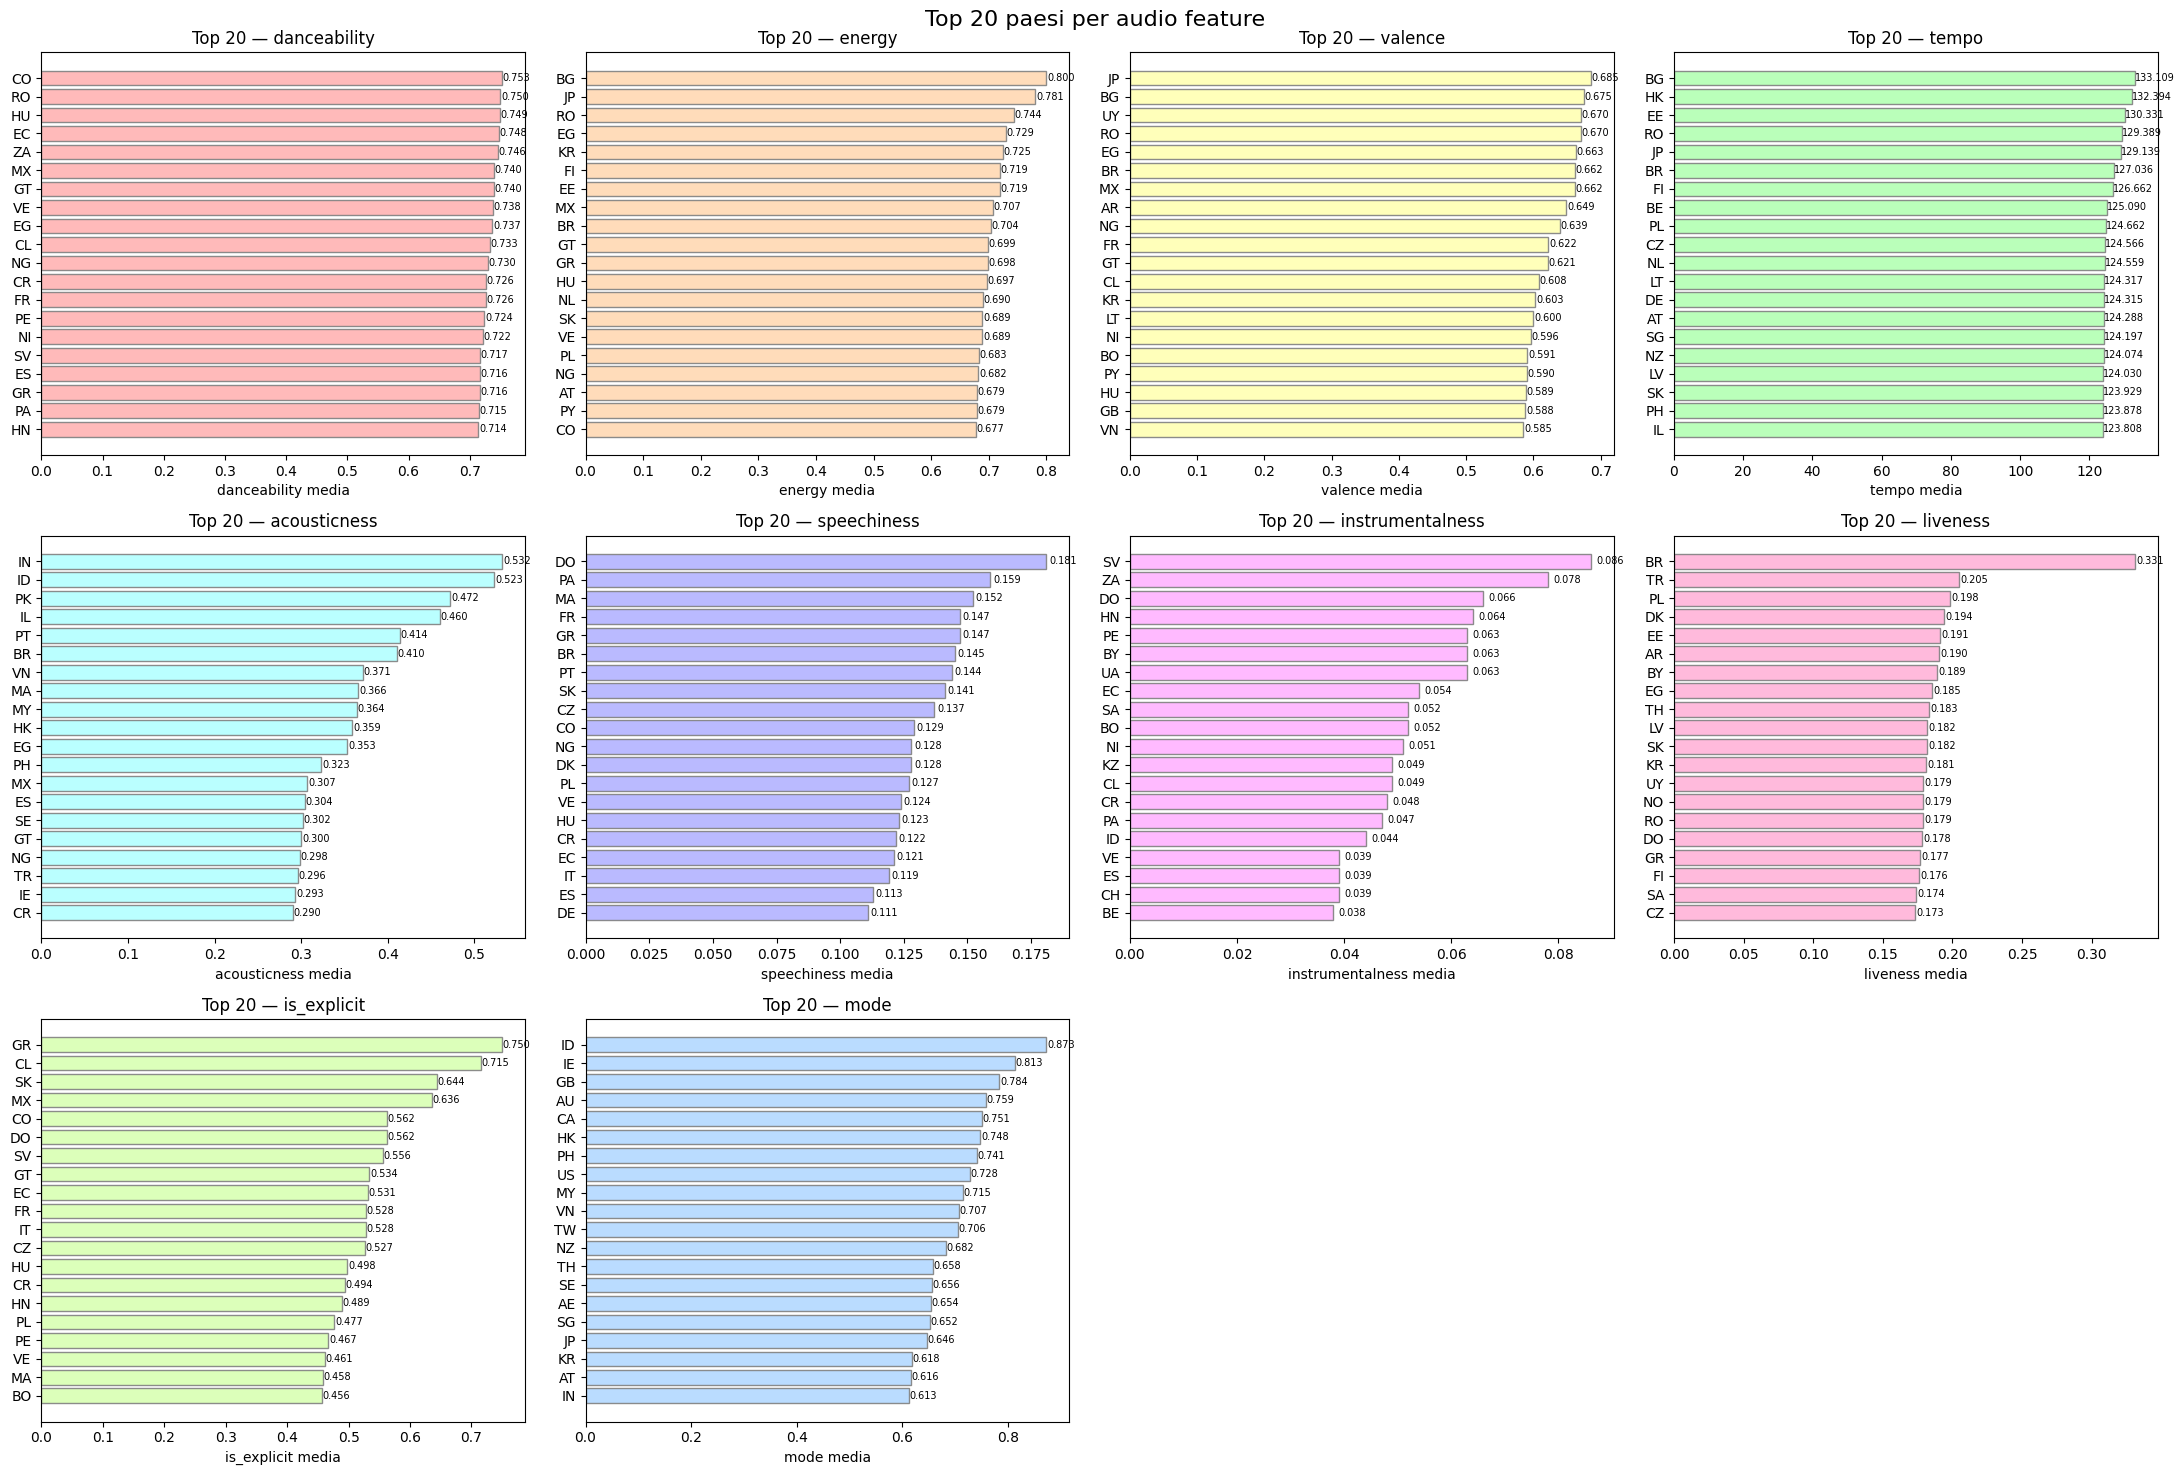

In [ ]:
# Tutti in un unico Subplot
features_plot = ['danceability', 'energy', 'valence', 'tempo',
                 'acousticness', 'speechiness', 'instrumentalness',
                 'liveness','is_explicit','mode']

colori = [
    '#FFB3B3',  # rosa
    '#FFD9B3',  # pesca
    '#FFFFB3',  # giallo
    '#B3FFB3',  # verde menta
    '#B3FFFF',  # azzurro
    '#B3B3FF',  # lavanda
    '#FFB3FF',  # lilla
    '#FFB3D9',  # rosa antico
    '#D9FFB3',  # verde lime
    '#B3D9FF',  # celeste
]

fig, axes = plt.subplots(3, 4, figsize=(22, 15))
axes = axes.flatten()

for i, feature in enumerate(features_plot):
    top_20 = df_paese[feature].sort_values(ascending=False).head(20)

    axes[i].barh(top_20.index, top_20.values,
                 color=colori[i], edgecolor='gray', alpha=0.9)
    axes[i].set_title(f'Top 20 — {feature}')
    axes[i].set_xlabel(f'{feature} media')
    axes[i].invert_yaxis()

    for bar, val in zip(axes[i].patches, top_20.values):
        axes[i].text(val + 0.001, bar.get_y() + bar.get_height()/2,
                     f'{val:.3f}', va='center', fontsize=7)

# Nascondo subplot vuoti
axes[10].set_visible(False)
axes[11].set_visible(False)

plt.suptitle('Top 20 paesi per audio feature', fontsize=16)
plt.tight_layout()
plt.show()

### Correlazione tra Audio Features per Paese

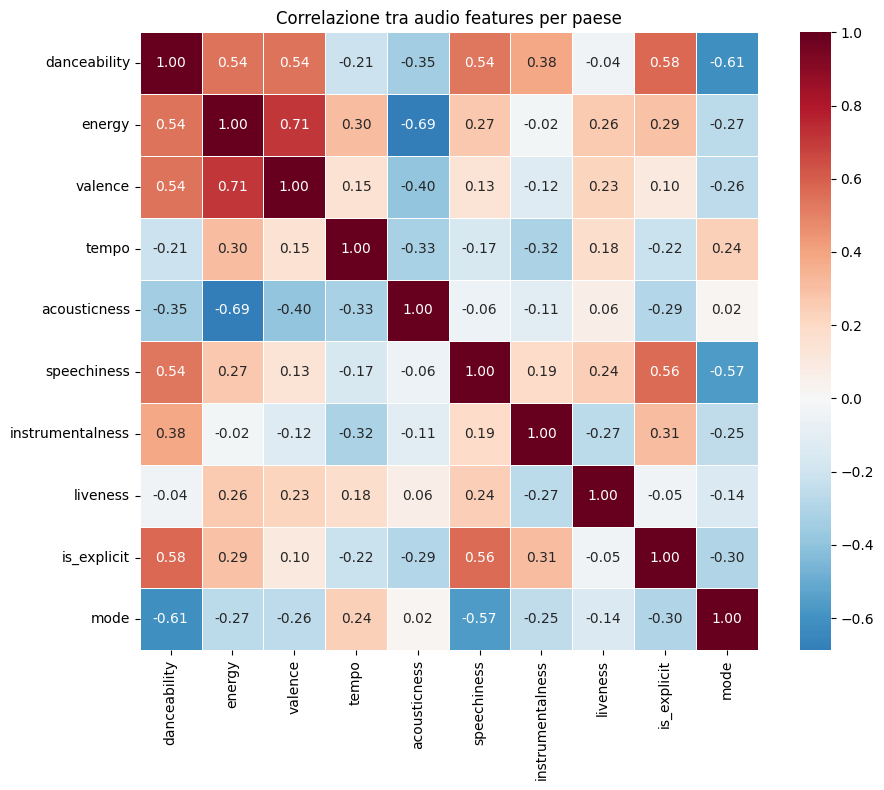

In [ ]:
plt.figure(figsize=(10,8))
corr = df_paese.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidth=0.5)
plt.title('Correlazione tra audio features per paese')
plt.tight_layout()
plt.show()

## Profilo per Artista


### Separiamo le Collaborazioni

In [ ]:
# Separiamo le collaborazioni
df_exploded = df_clean.copy()
df_exploded['artists'] = df_exploded['artists'].str.split(', ')
df_exploded = df_exploded.explode('artists')

print(f"Righe prima: {df_clean.shape[0]}")
print(f"Righe dopo explode: {df_exploded.shape[0]}")
print(f"Artisti unici: {df_exploded['artists'].nunique()}")

Righe prima: 2070048
Righe dopo explode: 3299411
Artisti unici: 11890


### Calcoliamo il Profilo Sonoro Medio per Artista

In [ ]:
features_cluster = ['danceability', 'energy', 'valence', 'tempo',
                    'acousticness', 'speechiness', 'instrumentalness',
                    'liveness','is_explicit','mode']

df_artisti = df_exploded.groupby('artists')[features_cluster].mean().round(3)
df_artisti = df_artisti.reset_index()

print(f"Artisti profilati: {df_artisti.shape[0]}")
df_artisti

Artisti profilati: 11890


,artists,danceability,energy,valence,tempo,acousticness,speechiness,instrumentalness,liveness,is_explicit,mode
0,#nācgavilēt koris,0.511,0.606,0.344,84.064,0.019,0.029,0.0,0.176,0.000,0.000
1,$A Lil Van,0.823,0.813,0.746,150.051,0.118,0.155,0.0,0.845,0.000,0.000
2,$OHO BANI,0.692,0.644,0.354,139.746,0.090,0.117,0.0,0.131,0.994,0.998
3,$ONO$ CLIQ,0.902,0.904,0.864,143.992,0.061,0.121,0.0,0.089,1.000,0.000
4,$hirak,0.854,0.612,0.699,128.493,0.278,0.269,0.0,0.129,0.902,0.123
...,...,...,...,...,...,...,...,...,...,...,...
11885,馬天佑,0.520,0.432,0.575,119.995,0.796,0.038,0.0,0.294,0.000,1.000
11886,高爾宣 OSN,0.636,0.678,0.277,81.282,0.273,0.063,0.0,0.207,0.210,0.998
11887,고추잠자리,0.586,0.581,0.268,109.969,0.058,0.025,0.0,0.113,0.000,1.000
11888,데이먼스 이어 Damons year,0.483,0.469,0.317,109.259,0.658,0.032,0.0,0.188,0.000,1.000


In [ ]:
# Salviamo tutto su Colab
from google.colab import drive
drive.mount('/content/drive')

PATH = '/content/drive/MyDrive/FestivalFit/'

df_paese.to_csv(PATH + 'paese_profilo.csv')
df_artisti.to_csv(PATH + 'artisti_profilo.csv', index=False)

print(f"Paese: {df_paese.shape}")
print(f"Artisti: {df_artisti.shape}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Paese: (72, 10)
Artisti: (11890, 11)


## K-MEANS CLUSTERING

### Normalizziamo

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import  KMeans
from sklearn.metrics import silhouette_score

features_cluster = ['danceability', 'energy', 'valence', 'tempo',
                    'acousticness', 'speechiness', 'instrumentalness',
                    'liveness','is_explicit','mode']

# Normalizziamo
scaler = StandardScaler()
df_paese_scaled = scaler.fit_transform(df_paese[features_cluster])

print(f"Shape scalata: {df_paese_scaled.shape}")
print(f"Media: {df_paese_scaled.mean(axis=0).round(2)}")
print(f"Std: {df_paese_scaled.std(axis=0).round(2)}")

Shape scalata: (72, 10)
Media: [ 0.  0.  0. -0.  0. -0.  0. -0.  0. -0.]
Std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### Troviamo il numero ottimale di Cluster con Elbow + Silhouette

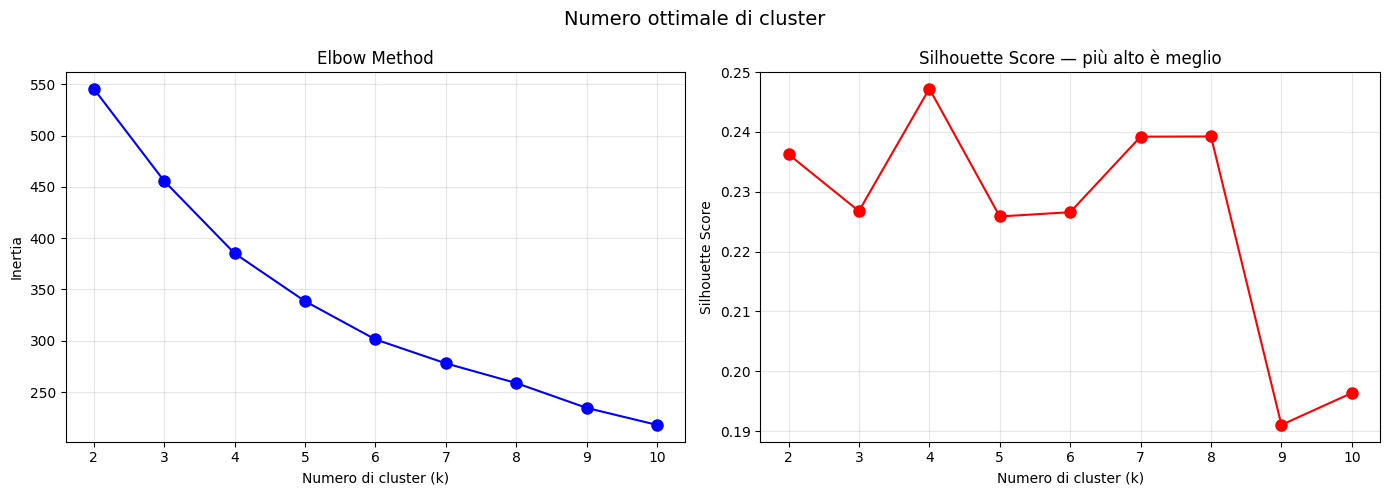

In [ ]:
inertia = []
silhouette = []
K = range(2, 11)

#Per ogni valore di K da 2 a 10 (2,11) allena un KMeans e
#salva due metriche : inertia e silhouette

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(df_paese_scaled)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(df_paese_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
#2 Grafici
#Elbow Method
axes[0].plot(K, inertia, 'bo-', markersize=8)
axes[0].set_xlabel('Numero di cluster (k)')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method')
axes[0].set_xticks(K)
axes[0].grid(True, alpha=0.3)

#Silhouette Score
axes[1].plot(K, silhouette, 'ro-', markersize=8)
axes[1].set_xlabel('Numero di cluster (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score — più alto è meglio')
axes[1].set_xticks(K)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Numero ottimale di cluster', fontsize=14)
plt.tight_layout()
plt.show()

### Paesi per Cluster

In [ ]:
# K-Means con k=5
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df_paese['cluster'] = kmeans.fit_predict(df_paese_scaled)

print(df_paese['cluster'].value_counts())

# Vediamo i paesi per cluster
for i in range(5):
    paesi = df_paese[df_paese['cluster'] == i].index.tolist()
    print(f"\nCluster {i} ({len(paesi)} paesi): {paesi}")

cluster
2    31
1    20
0    15
3     5
4     1
Name: count, dtype: int64

Cluster 0 (15 paesi): ['AR', 'AT', 'BG', 'DE', 'EE', 'EG', 'FI', 'JP', 'KR', 'LT', 'LV', 'MX', 'NL', 'RO', 'UY']

Cluster 1 (20 paesi): ['AE', 'AU', 'BE', 'CA', 'CH', 'GB', 'HK', 'IE', 'IS', 'LU', 'NO', 'NZ', 'PH', 'SA', 'SE', 'SG', 'TH', 'TW', 'US', 'VN']

Cluster 2 (31 paesi): ['BO', 'BY', 'CL', 'CO', 'CR', 'CZ', 'DK', 'DO', 'EC', 'ES', 'FR', 'GR', 'GT', 'HN', 'HU', 'IT', 'KZ', 'MA', 'NG', 'NI', 'PA', 'PE', 'PL', 'PT', 'PY', 'SK', 'SV', 'TR', 'UA', 'VE', 'ZA']

Cluster 3 (5 paesi): ['ID', 'IL', 'IN', 'MY', 'PK']

Cluster 4 (1 paesi): ['BR']


In [ ]:
nomi_cluster = nomi_cluster = {
    0: 'High Energy Pop',
    1: 'Pop Mainstream',
    2: 'Latin Groove',
    3: 'Asian Acoustic',
    4: 'Brazilian Beat'
}

df_paese['cluster_name'] = df_paese['cluster'].map(nomi_cluster)

print(df_paese['cluster_name'].value_counts())

cluster_name
Latin Groove       31
Pop Mainstream     20
High Energy Pop    15
Asian Acoustic      5
Brazilian Beat      1
Name: count, dtype: int64


### Caratteristiche medie per Cluster

In [ ]:
# Caratteristiche medie per cluster
cluster_profile = df_paese.groupby('cluster_name')[features_cluster].mean().round(3)
print(cluster_profile)

                 danceability  energy  valence    tempo  acousticness  \
cluster_name                                                            
Asian Acoustic          0.600   0.538    0.449  116.709         0.470   
Brazilian Beat          0.689   0.704    0.662  127.036         0.410   
High Energy Pop         0.691   0.709    0.618  124.199         0.206   
Latin Groove            0.712   0.663    0.557  116.870         0.259   
Pop Mainstream          0.650   0.629    0.546  121.403         0.265   

                 speechiness  instrumentalness  liveness  is_explicit   mode  
cluster_name                                                                  
Asian Acoustic         0.063             0.018     0.159        0.057  0.569  
Brazilian Beat         0.145             0.003     0.331        0.238  0.455  
High Energy Pop        0.083             0.018     0.173        0.267  0.506  
Latin Groove           0.119             0.038     0.164        0.452  0.437  
Pop Mainstream

In [ ]:
# Media globale
media_globale = df_paese[features_cluster].mean().round(3)
print("=== Media globale ===")
print(media_globale)

=== Media globale ===
danceability          0.682
energy                0.655
valence               0.561
tempo               119.786
acousticness          0.266
speechiness           0.095
instrumentalness      0.025
liveness              0.167
is_explicit           0.334
mode                  0.526
dtype: float64


In [ ]:
# Salviamo df_paese aggiornato
df_paese.to_csv(PATH + 'paese_profilo.csv')

### Pair Plot

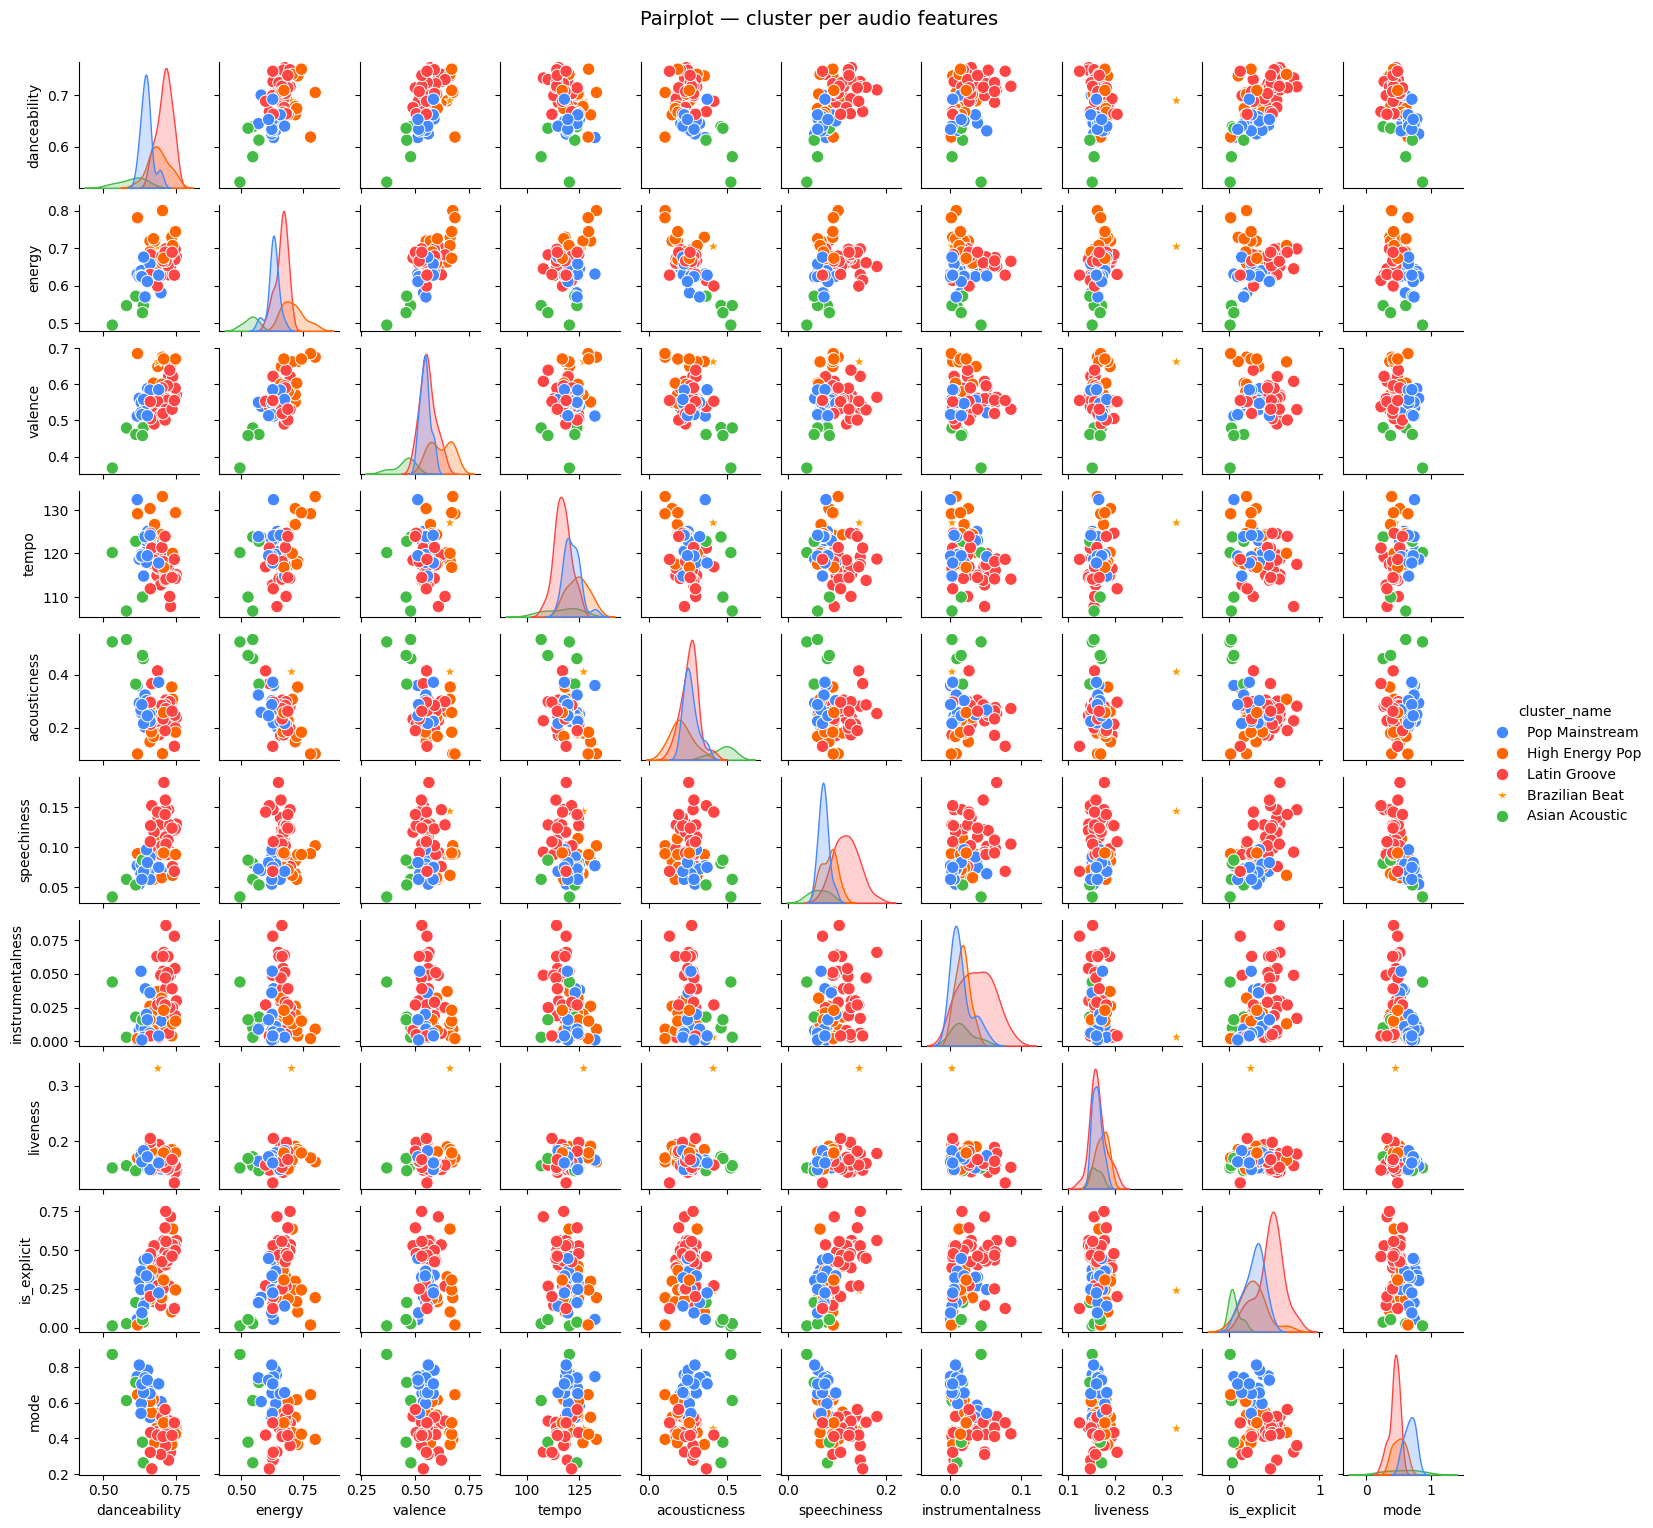

In [ ]:
colori_cluster = {
    'High Energy Pop': '#FF6600',
    'Pop Mainstream': '#4488FF',
    'Latin Groove': '#FF4444',
    'Asian Acoustic': '#44BB44',
    'Brazilian Beat': '#FF9900'
}


markers_ordinati = ['o',  # Pop Mainstream
                    'o',  # High Energy Pop
                    'o',  # Latin Groove
                    '*',  # Brazilian Beat ← stella!
                    'o']  # Asian Acoustic


sns.pairplot(df_paese,
             hue='cluster_name',
             palette=colori_cluster,
             markers=markers_ordinati,
             height=1.5,
             plot_kws={'s': 80},
             vars=features_cluster)

plt.suptitle('Pairplot — cluster per audio features', y=1.02, fontsize=14)
plt.show()

## K-Means per predirre il Cluster dell'Artista in base al sup Profilo Sonoro

In [ ]:
# Normalizziamo df_artisti con lo stesso scaler usato per df_paese
X_artisti = df_artisti[features_cluster]
X_artisti_scaled = scaler.transform(X_artisti)

# Assegniamo il cluster agli artisti usando il modello già addestrato
df_artisti['cluster'] = kmeans.predict(X_artisti_scaled)
df_artisti['cluster_name'] = df_artisti['cluster'].map(nomi_cluster)

print(df_artisti['cluster_name'].value_counts())

cluster_name
Latin Groove       3607
High Energy Pop    2665
Asian Acoustic     2156
Brazilian Beat     2090
Pop Mainstream     1372
Name: count, dtype: int64


## Model Selection

In [ ]:
df_paese.to_csv(PATH + 'paese_profilo.csv')
df_artisti.to_csv(PATH + 'artisti_profilo.csv', index=False)
df_clean.to_csv(PATH + 'countries_clean.csv', index=False)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

PATH = '/content/drive/MyDrive/FestivalFit/'

df_clean   = pd.read_csv(PATH + 'countries_clean.csv')
df_paese   = pd.read_csv(PATH + 'paese_profilo.csv', index_col=0)
df_artisti = pd.read_csv(PATH + 'artisti_profilo.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
print(f"Clean:   {df_clean.shape}")
print(f"Paese:   {df_paese.shape}")
print(f"Artisti: {df_artisti.shape}")

Clean:   (2070048, 20)
Paese:   (72, 12)
Artisti: (11890, 13)


In [ ]:
print(df_artisti.columns.tolist())
print(df_artisti.dtypes)

['artists', 'danceability', 'energy', 'valence', 'tempo', 'acousticness', 'speechiness', 'instrumentalness', 'liveness', 'is_explicit', 'mode', 'cluster', 'cluster_name']
artists              object
danceability        float64
energy              float64
valence             float64
tempo               float64
acousticness        float64
speechiness         float64
instrumentalness    float64
liveness            float64
is_explicit         float64
mode                float64
cluster               int64
cluster_name         object
dtype: object


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, classification_report

# Features e target
X = df_artisti[features_cluster]
y = df_artisti['cluster']

# Train/test split 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Normalizziamo
scaler_ml = StandardScaler()
X_train_scaled = scaler_ml.fit_transform(X_train)
X_test_scaled = scaler_ml.transform(X_test)

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

Train: (9512, 10)
Test:  (2378, 10)


In [ ]:
classifiers = [
    DecisionTreeClassifier(max_depth=4),
    RandomForestClassifier(n_estimators=200, random_state=42),
    GradientBoostingClassifier(),
    GradientBoostingClassifier(n_estimators=50),
    LogisticRegression(max_iter=1000),
    GaussianNB(),
    KNeighborsClassifier(n_neighbors=2),
    SVC(probability=True, kernel='rbf'),
    XGBClassifier()
]

In [ ]:
for cls in classifiers:
    cls.fit(X_train_scaled, y_train)
    cls.predict(X_test_scaled)

### Confusion Matrix

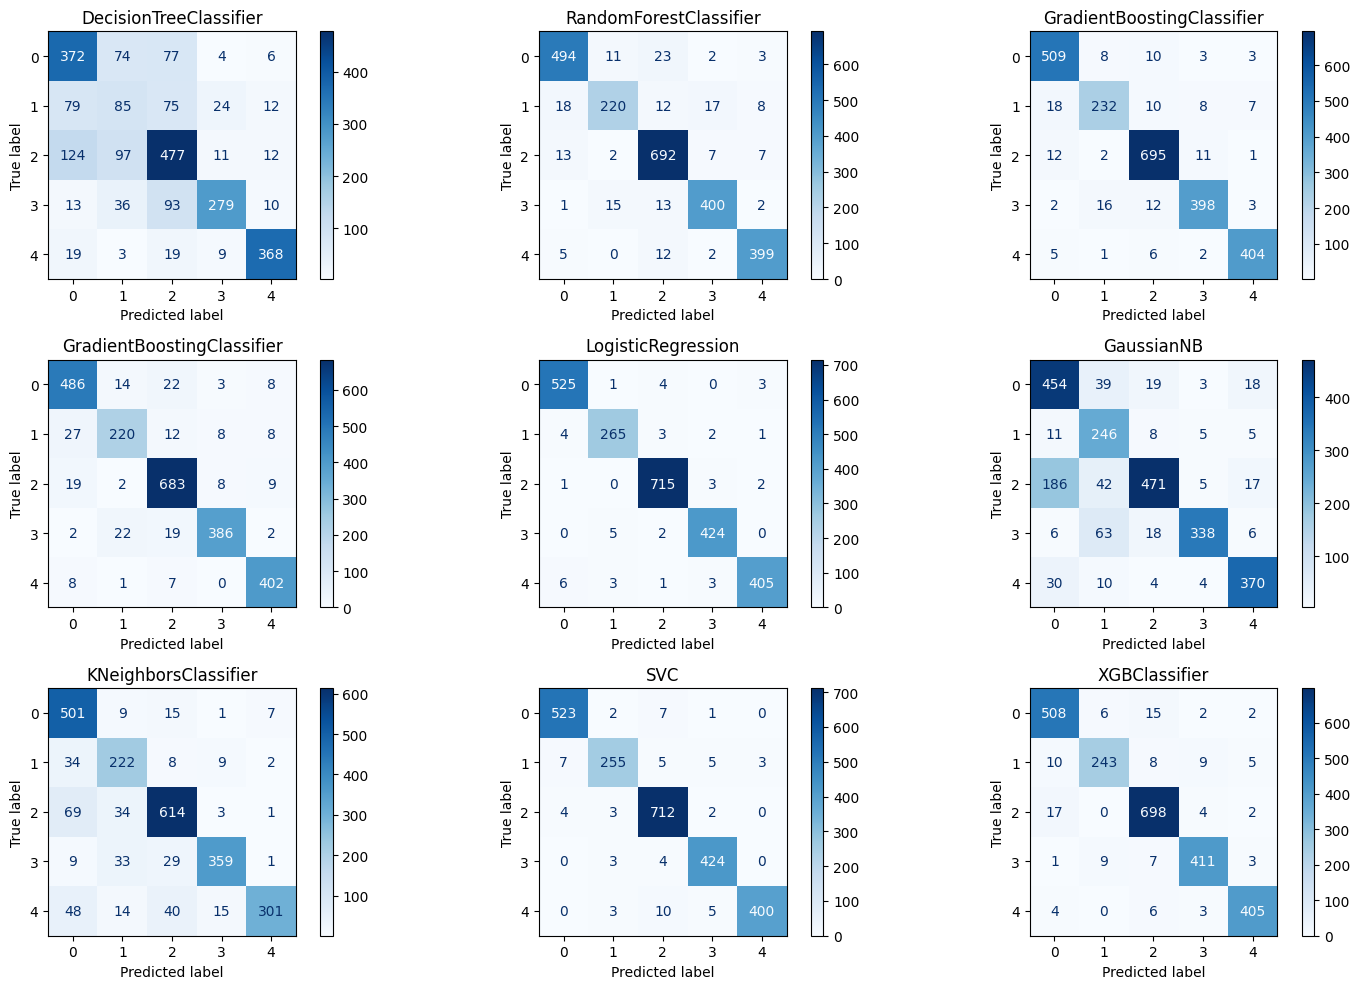

In [ ]:
# Confusion Matrix per tutti
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 10))

# Labels dei tuoi cluster
labels = ['High Energy Pop', 'Pop Mainstream', 'Latin Groove',
          'Asian Acoustic', 'Brazilian Beat']

for cls, ax in zip(classifiers, axes.flatten()):
    ConfusionMatrixDisplay.from_estimator(cls,
                                          X_test_scaled,
                                          y_test,
                                          ax=ax,
                                          cmap='Blues')
    ax.title.set_text(type(cls).__name__)

plt.tight_layout()
plt.show()

### Classification Report

In [ ]:
from sklearn.metrics import classification_report

for cls in classifiers:
    print(cls)
    print(classification_report(y_test, cls.predict(X_test_scaled), target_names=labels))

DecisionTreeClassifier(max_depth=4)
                 precision    recall  f1-score   support

High Energy Pop       0.61      0.70      0.65       533
 Pop Mainstream       0.29      0.31      0.30       275
   Latin Groove       0.64      0.66      0.65       721
 Asian Acoustic       0.85      0.65      0.74       431
 Brazilian Beat       0.90      0.88      0.89       418

       accuracy                           0.66      2378
      macro avg       0.66      0.64      0.65      2378
   weighted avg       0.68      0.66      0.67      2378

RandomForestClassifier(n_estimators=200, random_state=42)
                 precision    recall  f1-score   support

High Energy Pop       0.93      0.93      0.93       533
 Pop Mainstream       0.89      0.80      0.84       275
   Latin Groove       0.92      0.96      0.94       721
 Asian Acoustic       0.93      0.93      0.93       431
 Brazilian Beat       0.95      0.95      0.95       418

       accuracy                           0.93

## Fine Tune RandomForest con CrossValidation e GridSearch

### GridSearch

In [ ]:
from sklearn.model_selection import GridSearchCV

# Creiamo la griglia dei parametri
param_grid = {
                #'bootstrap': [True],
                'max_depth': [10,20,None],
                #'max_features': [2, 3],
                #'min_samples_leaf': [3, 4, 5],
                'min_samples_split': [2,5],
                'n_estimators': [100, 200]
            }

rf = RandomForestClassifier(random_state=42)
grid_search_rf = GridSearchCV(estimator = rf,
                            param_grid = param_grid,
                            cv = 5,
                            n_jobs = -1,
                            verbose = 2
                            )

In [ ]:
%%time
grid_search_rf.fit(X_train_scaled, y_train)
print(grid_search_rf.best_params_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
{'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}
CPU times: user 6.45 s, sys: 174 ms, total: 6.63 s
Wall time: 3min 2s


### Valutiamo il modello ottimizzato

In [ ]:
from sklearn.metrics import accuracy_score

def evaluate(model, X_test, y_test):
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test,y_pred)
    print('Model Performance')
    print(f'Accuracy score: {acc:0.2f} %')
    return  round(acc,2)

best_grid = grid_search_rf.best_estimator_
grid_accuracy = evaluate(best_grid, X_test_scaled, y_test)
grid_accuracy

Model Performance
Accuracy score: 0.93 %


0.93

### Feature Importance

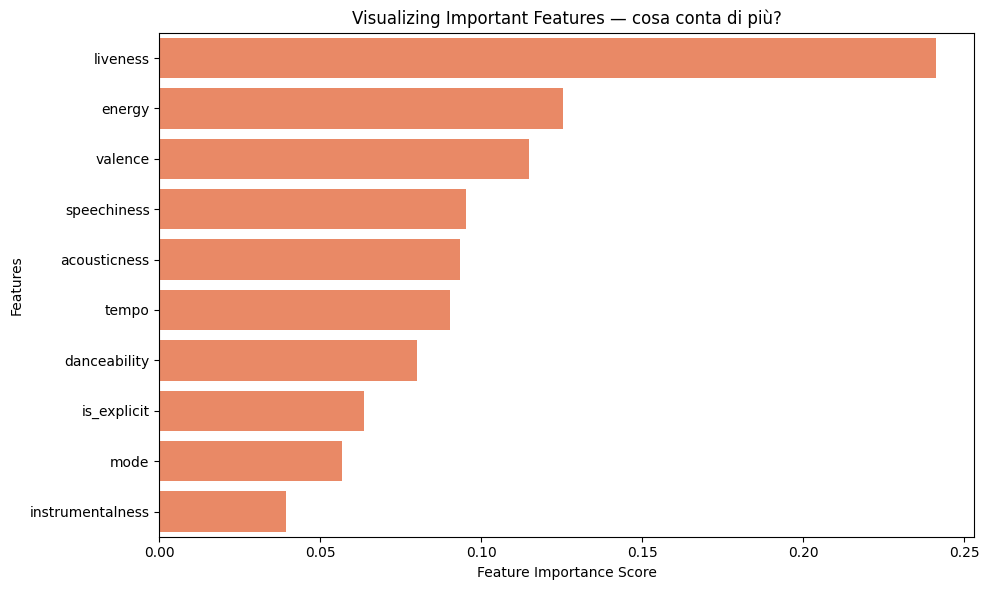

liveness            0.241
energy              0.125
valence             0.115
speechiness         0.095
acousticness        0.093
tempo               0.090
danceability        0.080
is_explicit         0.064
mode                0.057
instrumentalness    0.039
dtype: float64


In [ ]:
feature_imp = pd.Series(best_grid.feature_importances_,
                        index=features_cluster).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feature_imp, y=feature_imp.index, color='coral')
plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.title('Visualizing Important Features — cosa conta di più?')
plt.tight_layout()
plt.show()

print(feature_imp.round(3))

In [ ]:
#Salvo tutto su Drive
import joblib

# Salva dataset
df_paese.to_csv(PATH + 'paese_profilo.csv')
df_artisti.to_csv(PATH + 'artisti_profilo.csv', index=False)
df_clean.to_csv(PATH + 'countries_clean.csv', index=False)

# Salva modelli
joblib.dump(scaler, PATH + 'scaler_kmeans.pkl')
joblib.dump(kmeans, PATH + 'kmeans_model.pkl')

print("✅ Tutto salvato su Google Drive!")

✅ Tutto salvato su Google Drive!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd

PATH = '/content/drive/MyDrive/FestivalFit/'
df_clean = pd.read_csv(PATH + 'countries_clean.csv')
df_artisti = pd.read_csv(PATH + 'artisti_profilo.csv')

pop_media = df_clean.groupby('artists')['popularity'].mean().round(1)
df_artisti['popularity'] = df_artisti['artists'].map(pop_media)
df_artisti.to_csv('artisti_profilo.csv', index=False)

from google.colab import files
files.download('artisti_profilo.csv')

Mounted at /content/drive


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(df_clean['snapshot_date'].min())
print(df_clean['snapshot_date'].max())


2023-10-18
2025-06-11


In [ ]:
df_clean['snapshot_date'] = pd.to_datetime(df_clean['snapshot_date'])
df_small = df_clean[df_clean['snapshot_date'] >= '2024-06-01']

cols = ['country', 'artists', 'snapshot_date', 'popularity',
        'danceability', 'energy', 'valence', 'tempo',
        'acousticness', 'speechiness', 'instrumentalness',
        'liveness', 'is_explicit', 'mode']

df_small = df_small[cols]
print(f"Righe originali: {len(df_clean)}")
print(f"Righe ridotte: {len(df_small)}")
print(f"Dimensione stimata: {df_small.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

df_small.to_csv('countries_clean.csv', index=False)

from google.colab import files
files.download('countries_clean.csv')


Righe originali: 2070048
Righe ridotte: 1272573
Dimensione stimata: 271.7 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>